<a href="https://colab.research.google.com/github/anupbagale/neural-networks-from-scratch/blob/main/notebooks/06_backpropagation_xor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lesson 6: Backpropagation on XOR

Lesson 6 of 8, about 40 minutes.

After this lesson you should be able to:

1. Derive the backpropagation updates for a network with one hidden layer.
2. Train a 2-2-1 network on XOR, which a single neuron cannot learn.
3. Check backpropagation against a numerical gradient.
4. See how the hidden layer turns XOR into a linearly separable problem.

You will need: lessons 1, 2 and 5, and matrix-vector products.

In [1]:
# Setup (works locally and on Google Colab)
try:
    import nnlab
except ImportError:  # not installed yet, e.g. on Colab
    %pip install -q "git+https://github.com/anupbagale/neural-networks-from-scratch"
    import nnlab

import numpy as np
import matplotlib.pyplot as plt
from nnlab.style import apply_style, PALETTE

apply_style()
np.set_printoptions(precision=3, suppress=True)

## The network

In lesson 1 we solved XOR with a hidden layer designed by hand. This time the network learns the
hidden layer itself.

The input is $\mathbf{x} = [x_1,\ x_2,\ 1]$, where the constant 1 is the bias input. The hidden
layer has $J = 2$ units with bipolar sigmoid activations, $\mathbf{y} = f(V\mathbf{x})$, and a
bias unit is appended to give $\tilde{\mathbf{y}} = [y_1,\ y_2,\ 1]$. The output is
$o = f(\mathbf{w}^\top\tilde{\mathbf{y}})$.

$V$ is a $2 \times 3$ matrix (input to hidden) and $\mathbf{w}$ has 3 entries (hidden to output).

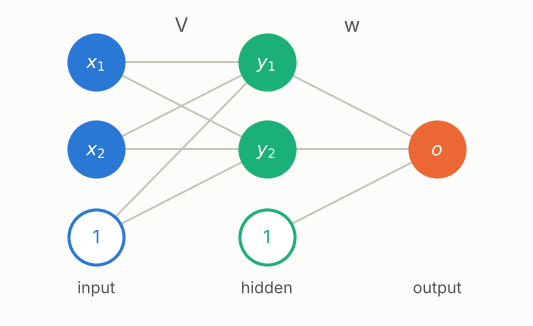

In [2]:
def draw_network(ax):
    layers = {"x": [(0, 2), (0, 1), (0, 0)], "y": [(1, 2), (1, 1), (1, 0)], "o": [(2, 1)]}
    names = {"x": ["$x_1$", "$x_2$", "1"], "y": ["$y_1$", "$y_2$", "1"], "o": ["$o$"]}
    for (a, b, lbl, idx) in [("x", "y", "V", [0, 1]), ("y", "o", "w", [0])]:
        for p in layers[a]:
            for k in idx:
                q = layers[b][k]
                ax.plot([p[0], q[0]], [p[1], q[1]], color="#c3c2b7", lw=1.2, zorder=1)
        ax.text((layers[a][0][0] + layers[b][0][0]) / 2, 2.35, lbl, ha="center", fontsize=13, color="#52514e")
    for key, color in [("x", PALETTE[0]), ("y", PALETTE[2]), ("o", PALETTE[1])]:
        for (x, y), name in zip(layers[key], names[key]):
            bias = name == "1"
            ax.scatter(x, y, s=1300, color="white" if bias else color, edgecolor=color, linewidth=2, zorder=2)
            ax.text(x, y, name, ha="center", va="center", fontsize=12,
                    color=color if bias else "white", zorder=3)
    for x, t in [(0, "input"), (1, "hidden"), (2, "output")]:
        ax.text(x, -0.65, t, ha="center", color="#52514e")
    ax.set(xlim=(-0.5, 2.5), ylim=(-0.9, 2.6))
    ax.axis("off")

fig, ax = plt.subplots(figsize=(6, 3.6))
draw_network(ax)
plt.show()

## Deriving backpropagation

For one pattern the error is $E = \tfrac12 (d - o)^2$. The output layer is handled exactly like the
delta rule:

$$
\delta_o = (d - o)\, f'(net_o) = (d - o)\,\tfrac12(1 - o^2), \qquad
\Delta\mathbf{w} = \eta\,\delta_o\,\tilde{\mathbf{y}}.
$$

The hidden units have no target of their own, but the chain rule tells us how much each one
contributed to $E$. The output error is passed backwards through the weight that connects each
hidden unit to the output:

$$
\delta_{y_j} = f'(net_{y_j}) \cdot w_j\,\delta_o = \tfrac12(1 - y_j^2)\, w_j\, \delta_o, \qquad
\Delta V = \eta\, \boldsymbol{\delta}_y\, \mathbf{x}^\top .
$$

So one training step is: a forward pass, the output delta, the hidden deltas, and then an update of
both layers. Each line of `TwoLayerNet.train_step` in `nnlab/backprop.py` matches one of these
equations:

In [3]:
import inspect
from nnlab.backprop import TwoLayerNet
print(inspect.getsource(TwoLayerNet.train_step))

    def train_step(self, x: Sequence[float], d: float) -> float:
        """Present one pattern, update both layers, return its error ``½(d − o)²``."""
        x = np.asarray(x, dtype=float)
        y = self.hidden(x)
        o = float(bipolar_sigmoid(self.W @ y, self.lam))

        delta_o = (d - o) * bipolar_sigmoid_derivative(o, self.lam)
        delta_y = self.W * delta_o * bipolar_sigmoid_derivative(y, self.lam)
        delta_y = delta_y[:-1]  # the bias unit has no incoming weights

        self.W = self.W + self.lr * delta_o * y
        self.V = self.V + self.lr * np.outer(delta_y, x)
        return 0.5 * (d - o) ** 2



## Training on XOR

We use the starting weights and learning rate from the original lab:
$V = \begin{bmatrix} 1 & -1 & -1 \\ 1 & -2 & 1 \end{bmatrix}$, $\mathbf{w} = [1,\ 1,\ -1]$,
$\eta = 0.05$, targets $d = [0, 1, 1, 0]$, and stop when the total error falls below $0.01$.

In [4]:
X = np.array([[0, 0, 1], [0, 1, 1], [1, 0, 1], [1, 1, 1]], dtype=float)
d = np.array([0, 1, 1, 0], dtype=float)

net = TwoLayerNet(V=[[1, -1, -1], [1, -2, 1]], W=[1, 1, -1], lr=0.05)
result = net.fit(X, d, max_epochs=10_000, tol=0.01)

print(f"converged: {result.converged} after {result.epochs} epochs")
print("V =\n", net.V)
print("w =", net.W)
for x, target, out in zip(X, d, net.predict(X)):
    print(f"x = {x[:2]}  target = {target:.0f}  output = {out:.3f}")

converged: True after 4494 epochs
V =
 [[ 3.074 -3.2   -1.533]
 [ 3.06  -3.179  1.672]]
w = [ 2.952 -2.972  3.961]
x = [0. 0.]  target = 0  output = 0.013
x = [0. 1.]  target = 1  output = 0.901
x = [1. 0.]  target = 1  output = 0.901
x = [1. 1.]  target = 0  output = 0.010


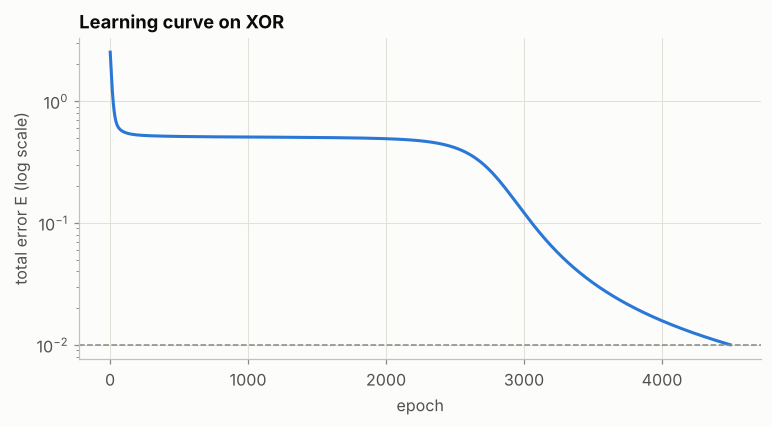

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(range(1, result.epochs + 1), result.epoch_errors, color=PALETTE[0])
ax.set(yscale="log", xlabel="epoch", ylabel="total error E (log scale)", title="Learning curve on XOR")
ax.axhline(0.01, color="#898781", ls="--", lw=1)
plt.show()

The error stays almost flat for a long time and then drops quickly. XOR often trains like this:
the network sits on a plateau until the two hidden units settle on different parts of the problem.

## Checking the gradient

It is easy to make a small mistake in backpropagation code that still lets the network learn
something. A gradient check compares each update with a finite-difference estimate,
$-\eta\,\dfrac{E(w + h) - E(w - h)}{2h}$. The two should agree to many decimal places.

In [6]:
def total_error(V, W, x, target):
    return 0.5 * (target - TwoLayerNet(V, W).forward(x)) ** 2

probe = TwoLayerNet(V=[[1, -1, -1], [1, -2, 1]], W=[1, 1, -1], lr=0.05)
x, target, h = X[2], d[2], 1e-6
V0, W0 = probe.V.copy(), probe.W.copy()
probe.train_step(x, target)

numeric_W = []
for i in range(W0.size):
    Wp, Wm = W0.copy(), W0.copy(); Wp[i] += h; Wm[i] -= h
    numeric_W.append(-probe.lr * (total_error(V0, Wp, x, target) - total_error(V0, Wm, x, target)) / (2 * h))

print("backprop Δw:", probe.W - W0)
print("numeric Δw: ", np.array(numeric_W))
print("max difference:", np.max(np.abs(probe.W - W0 - numeric_W)))

backprop Δw: [0.    0.021 0.028]
numeric Δw:  [-0.     0.021  0.028]
max difference: 1.9022526609457913e-12


## What the hidden layer does

The left plot shows the output of the trained network over the input square, with the boundaries of
the two hidden units ($V_j \cdot \mathbf{x} = 0$) drawn as lines. The right plot shows the four
training patterns as the hidden layer sees them, as points $(y_1, y_2)$. The two patterns with
target 0, $(0,0)$ and $(1,1)$, land on almost the same point, and a single line (where the output
equals 0.5) now separates the two classes.

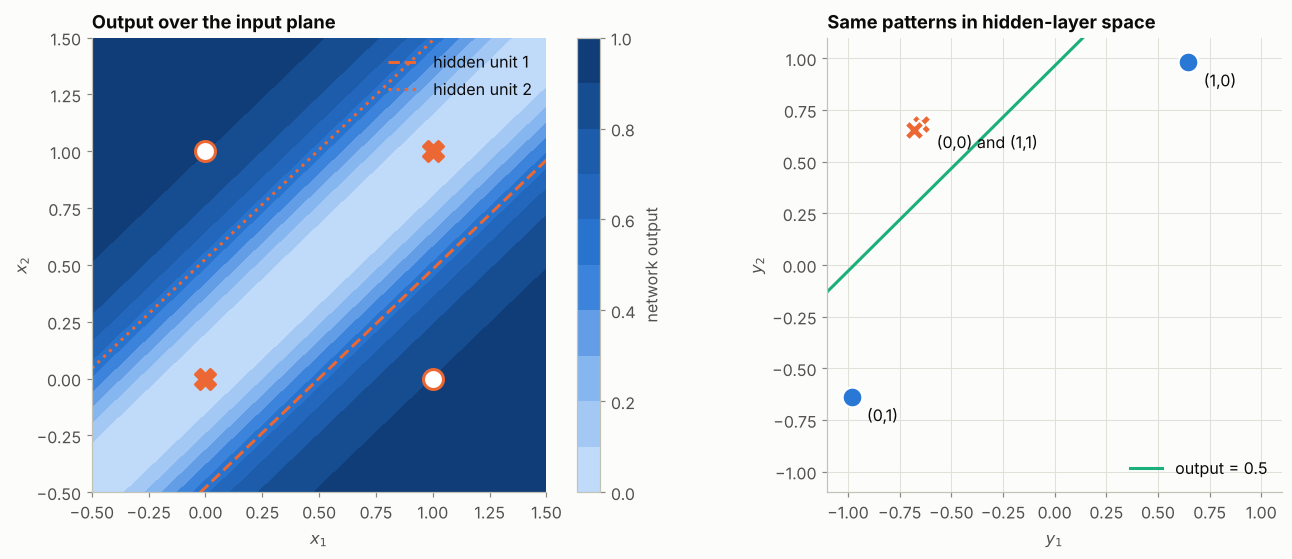

In [7]:
g = np.linspace(-0.5, 1.5, 250)
G1, G2 = np.meshgrid(g, g)
grid = np.column_stack([G1.ravel(), G2.ravel(), np.ones(G1.size)])
Z = net.predict(grid).reshape(G1.shape)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2))
im = ax1.contourf(G1, G2, np.clip(Z, 0, 1), levels=np.linspace(0, 1, 11), cmap="nnlab_seq")
fig.colorbar(im, ax=ax1, label="network output")
for j, ls in enumerate(["--", ":"]):
    v = net.V[j]
    ax1.plot(g, -(v[0] * g + v[2]) / v[1], color=PALETTE[1], ls=ls, lw=2, label=f"hidden unit {j + 1}")
for x_, t in zip(X, d):
    ax1.scatter(*x_[:2], s=170, marker="o" if t else "X", color="white" if t else PALETTE[1],
                edgecolor=PALETTE[1], linewidth=2, zorder=3)
ax1.set(xlim=(-0.5, 1.5), ylim=(-0.5, 1.5), xlabel="$x_1$", ylabel="$x_2$", aspect="equal",
        title="Output over the input plane")
ax1.legend(loc="upper right")

Y = np.array([net.hidden(x_)[:2] for x_ in X])
groups = []   # points that land on top of each other share one label
for (y1, y2), t, x_ in zip(Y, d, X):
    ax2.scatter(y1, y2, s=170, marker="o" if t else "X", color=PALETTE[0] if t else PALETTE[1],
                edgecolor="white", linewidth=1.5, zorder=3)
    name = f"({x_[0]:.0f},{x_[1]:.0f})"
    for g in groups:
        if np.hypot(g[0] - y1, g[1] - y2) < 0.15:
            g[2].append(name)
            break
    else:
        groups.append([y1, y2, [name]])
for y1, y2, names in groups:
    ax2.annotate(" and ".join(names), (y1, y2), textcoords="offset points", xytext=(10, -16))

# The targets are 0/1, so the natural decision threshold is o = 0.5,
# i.e. net_o = ln 3 for the bipolar sigmoid with λ = 1.
w = net.W
ys = np.linspace(-1.1, 1.1, 10)
ax2.plot(ys, (np.log(3) - w[0] * ys - w[2]) / w[1], color=PALETTE[2], lw=2, label="output = 0.5")
ax2.set(xlim=(-1.1, 1.1), ylim=(-1.1, 1.1), xlabel="$y_1$", ylabel="$y_2$", aspect="equal",
        title="Same patterns in hidden-layer space")
ax2.legend(loc="lower right")
fig.tight_layout()
plt.show()

## Learning rate and starting weights

In [8]:
rates = [0.05, 0.1, 0.2, 0.5, 1.0]
epochs = []
for lr in rates:
    r = TwoLayerNet(V=[[1, -1, -1], [1, -2, 1]], W=[1, 1, -1], lr=lr).fit(X, d, max_epochs=20_000)
    epochs.append(r.epochs if r.converged else np.nan)
    print(f"η = {lr:<4}  epochs = {r.epochs:>6}  converged = {r.converged}")

rng = np.random.default_rng(0)
outcomes = []
for trial in range(20):
    r = TwoLayerNet(V=rng.uniform(-1, 1, (2, 3)), W=rng.uniform(-1, 1, 3), lr=0.5).fit(X, d, max_epochs=20_000)
    outcomes.append(r.converged)
print(f"\nrandom starts with η = 0.5: {sum(outcomes)} of {len(outcomes)} converged")

η = 0.05  epochs =   4494  converged = True
η = 0.1   epochs =   2169  converged = True


η = 0.2   epochs =   1029  converged = True
η = 0.5   epochs =    385  converged = True


η = 1.0   epochs =  20000  converged = False



random starts with η = 0.5: 15 of 20 converged


Up to a point a larger learning rate reaches the tolerance in far fewer epochs. At $\eta = 1$,
though, training does not converge within 20,000 epochs, because the steps are large enough to keep
overshooting.

With random starting weights, some runs do not converge either. Typical reasons are a hidden unit
that saturates early or two hidden units that end up computing the same thing. In practice people
deal with this by restarting from new random weights, adding momentum, or using more hidden units
than the minimum.

## Exercises

1. The output unit is bipolar but the targets are 0 and 1. Change the targets to
   $d = [-1, 1, 1, -1]$. How many epochs does training need now, and why might that be?
2. Give the network $J = 3$ hidden units (`V` becomes $3\times3$ and `W` gets 4 entries). Do more
   of the random starts converge?

**Hint for exercise 1**

<details><summary>Answer</summary>

With 0/1 targets, the target 0 is in the middle of the bipolar output range, where the sigmoid is steepest, and the target 1 is near the upper limit. With $\pm1$ targets both classes are pushed towards the limits, where $f'(net)$ is small. Run it and compare. It is also worth comparing classification accuracy instead of the squared error, since the tolerance means something different in each case.

</details>

## Summary

- Backpropagation uses the chain rule to pass the output error δ back through the weights.
- A hidden unit's delta is its slope f′ times the weighted deltas of the units it feeds.
- The hidden layer maps the inputs to a space where the classes are linearly separable.
- Check gradients numerically, and expect some runs to get stuck.

Next: [Lesson 7, Bidirectional Associative Memory](07_bidirectional_associative_memory.ipynb)

### References

- Rumelhart, D. E., Hinton, G. E., & Williams, R. J. (1986). Learning representations by back-propagating errors. *Nature*, 323, 533–536.
- Minsky, M., & Papert, S. (1969). *Perceptrons: An Introduction to Computational Geometry*. MIT Press.
- Zurada, J. M. (1992). *Introduction to Artificial Neural Systems*. West Publishing Company.